# Exercício 

In [17]:
import os
import random
import re
import string
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from sklearn.metrics import accuracy_score, confusion_matrix
from spacy.lang.pt.stop_words import STOP_WORDS
from spacy.training import Example


In [6]:
DRIVE_DIRECTORY = Path.cwd().parent / "data" / "Twitter"
MODELS = Path.cwd().parent / "models"

In [9]:
base_dados = pd.read_csv(
    os.path.join(DRIVE_DIRECTORY, "Train50.csv"), sep=";"
)
base_dados

,id,tweet_text,tweet_date,sentiment,query_used
0,1050785521201541121,@Laranjito76 A pessoa certa para isso seria o ...,Fri Oct 12 16:29:25 +0000 2018,1,:)
1,1050785431955140608,"@behin_d_curtain Para mim, é precisamente o co...",Fri Oct 12 16:29:04 +0000 2018,1,:)
2,1050785401248645120,Vou fazer um video hoje... estou pensando em f...,Fri Oct 12 16:28:56 +0000 2018,1,:)
3,1050785370982547461,"aaaaaaaa amei tanto essas polaroids, nem sei e...",Fri Oct 12 16:28:49 +0000 2018,1,:)
4,1050785368902131713,Valoriza o coração do menininho que vc tem. El...,Fri Oct 12 16:28:49 +0000 2018,1,:)
...,...,...,...,...,...
49995,1046762827053232128,:( é tão lindo que dói https://t.co/GqnpgyWWxB,Mon Oct 01 14:04:40 +0000 2018,0,:(
49996,1046762813362966529,"@veraluciarj Pois é.. tenho problema c/ ""coisa...",Mon Oct 01 14:04:37 +0000 2018,0,:(
49997,1046762806392082432,eu te amo tanto minja vidinha meu bem mais pre...,Mon Oct 01 14:04:35 +0000 2018,0,:(
49998,1046762752071618560,@itsLary @jessboluda Pfvor :(,Mon Oct 01 14:04:22 +0000 2018,0,:(


In [10]:
base_dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          50000 non-null  int64
 1   tweet_text  50000 non-null  str  
 2   tweet_date  50000 non-null  str  
 3   sentiment   50000 non-null  int64
 4   query_used  50000 non-null  str  
dtypes: int64(2), str(3)
memory usage: 1.9 MB


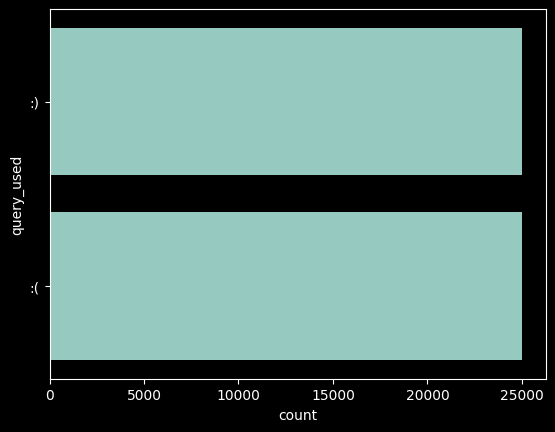

In [11]:
sns.countplot(base_dados['query_used'], label="Contagem");

In [12]:
pontuacoes = string.punctuation
pontuacoes

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [13]:
stop_words = STOP_WORDS
len(stop_words)

416

In [14]:
pln = spacy.load("pt_core_news_sm")
pln

In [22]:
def remove_user(texto):
    texto_sem_user = re.sub(r'@\w+', '', texto)
    return texto_sem_user.strip()

In [23]:
texto = """
Estou estudando PLN com @joao e @maria123.
O curso de @machine_learning está muito bom!
"""
print(remove_user(texto))

Estou estudando PLN com  e .
O curso de  está muito bom!


In [24]:
base_dados.head()

,id,tweet_text,tweet_date,sentiment,query_used
0,1050785521201541121,@Laranjito76 A pessoa certa para isso seria o ...,Fri Oct 12 16:29:25 +0000 2018,1,:)
1,1050785431955140608,"@behin_d_curtain Para mim, é precisamente o co...",Fri Oct 12 16:29:04 +0000 2018,1,:)
2,1050785401248645120,Vou fazer um video hoje... estou pensando em f...,Fri Oct 12 16:28:56 +0000 2018,1,:)
3,1050785370982547461,"aaaaaaaa amei tanto essas polaroids, nem sei e...",Fri Oct 12 16:28:49 +0000 2018,1,:)
4,1050785368902131713,Valoriza o coração do menininho que vc tem. El...,Fri Oct 12 16:28:49 +0000 2018,1,:)


In [25]:
base_dados['tweet_text'] = base_dados['tweet_text'].apply(remove_user)
base_dados.head()

,id,tweet_text,tweet_date,sentiment,query_used
0,1050785521201541121,A pessoa certa para isso seria o vale e azeved...,Fri Oct 12 16:29:25 +0000 2018,1,:)
1,1050785431955140608,"Para mim, é precisamente o contrário :) Vem a ...",Fri Oct 12 16:29:04 +0000 2018,1,:)
2,1050785401248645120,Vou fazer um video hoje... estou pensando em f...,Fri Oct 12 16:28:56 +0000 2018,1,:)
3,1050785370982547461,"aaaaaaaa amei tanto essas polaroids, nem sei e...",Fri Oct 12 16:28:49 +0000 2018,1,:)
4,1050785368902131713,Valoriza o coração do menininho que vc tem. El...,Fri Oct 12 16:28:49 +0000 2018,1,:)


In [26]:
def preprocessamento(texto):
    texto = texto.lower()
    documento = pln(texto)

    lista = []
    for token in documento:
        lista.append(token.lemma_)

    lista = [palavra for palavra in lista if palavra not in stop_words and palavra not in pontuacoes]
    lista = ' '.join([str(elemento) for elemento in lista if not elemento.isdigit()])

    return lista

In [27]:
base_dados['tweet_text'] = base_dados['tweet_text'].apply(preprocessamento)
base_dados.head()

,id,tweet_text,tweet_date,sentiment,query_used
0,1050785521201541121,pessoa certo vale azevedo :),Fri Oct 12 16:29:25 +0000 2018,1,:)
1,1050785431955140608,precisamente contrário :) vir chuva vir dispos...,Fri Oct 12 16:29:04 +0000 2018,1,:)
2,1050785401248645120,video hoje ... pensar falar meta de o csgo pag...,Fri Oct 12 16:28:56 +0000 2018,1,:)
3,1050785370982547461,aaaaaaaar amei polaroids expressar to apaixona...,Fri Oct 12 16:28:49 +0000 2018,1,:)
4,1050785368902131713,valorizar coração de o menininho vc diferente ...,Fri Oct 12 16:28:49 +0000 2018,1,:)


In [28]:
base_dados.to_csv(os.path.join(DRIVE_DIRECTORY, "Train_limpo.csv"), header=False)